# 01 - Data acquisition & EDA
Heart Disease UCI (Cleveland, 303 patients). This notebook downloads the data, cleans it and explores it. The plotting functions live in `src/heart/eda.py` so the same figures are produced by the script and the notebook.

In [1]:
import sys, pathlib
ROOT = pathlib.Path.cwd().parent if pathlib.Path.cwd().name == "notebooks" else pathlib.Path.cwd()
sys.path.insert(0, str(ROOT / "src")); sys.path.insert(0, str(ROOT))
import warnings; warnings.filterwarnings("ignore")

In [2]:
from heart import config
from heart.data import download_data, load_raw, clean_data, validate_data
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline

download_data()
raw = load_raw()
print(raw.shape)
raw.head()

(303, 14)


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,num
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,2
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,0
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,0


## Missing values
In the raw file missing values are written as `?`. Only `ca` (4 rows) and `thal` (2 rows) have them.

In [3]:
raw.isna().sum()[raw.isna().sum() > 0]

ca      4
thal    2
dtype: int64

In [4]:
df = clean_data(raw)
validate_data(df)
print(df.shape)
df.describe().T.round(2)

(303, 14)


,count,mean,std,min,25%,50%,75%,max
age,303.0,54.44,9.04,29.0,48.0,56.0,61.0,77.0
sex,303.0,0.68,0.47,0.0,0.0,1.0,1.0,1.0
cp,303.0,3.16,0.96,1.0,3.0,3.0,4.0,4.0
trestbps,303.0,131.69,17.60,94.0,120.0,130.0,140.0,200.0
chol,303.0,246.69,51.78,126.0,211.0,241.0,275.0,564.0
fbs,303.0,0.15,0.36,0.0,0.0,0.0,0.0,1.0
restecg,303.0,0.99,0.99,0.0,0.0,1.0,2.0,2.0
thalach,303.0,149.61,22.88,71.0,133.5,153.0,166.0,202.0
exang,303.0,0.33,0.47,0.0,0.0,0.0,1.0,1.0
oldpeak,303.0,1.04,1.16,0.0,0.0,0.8,1.6,6.2


## Class balance
The original `num` column is 0-4. Following the usual practice, any value > 0 is treated as *disease present*. The classes are fairly balanced (54% / 46%) so no resampling is needed; we still use a stratified split and stratified CV.

In [5]:
df[config.TARGET].value_counts(normalize=True).round(3)

target
0    0.541
1    0.459
Name: proportion, dtype: float64

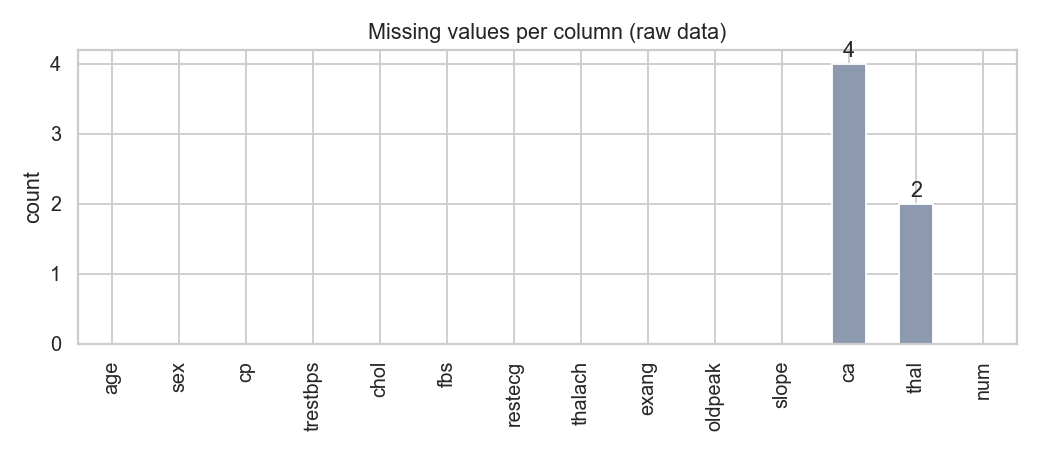

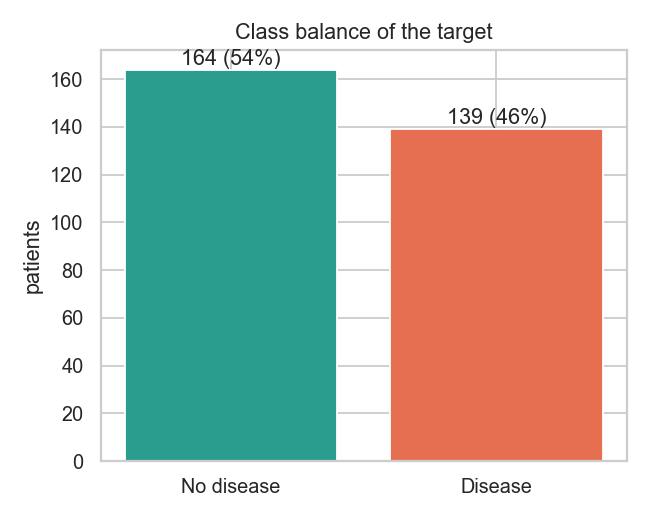

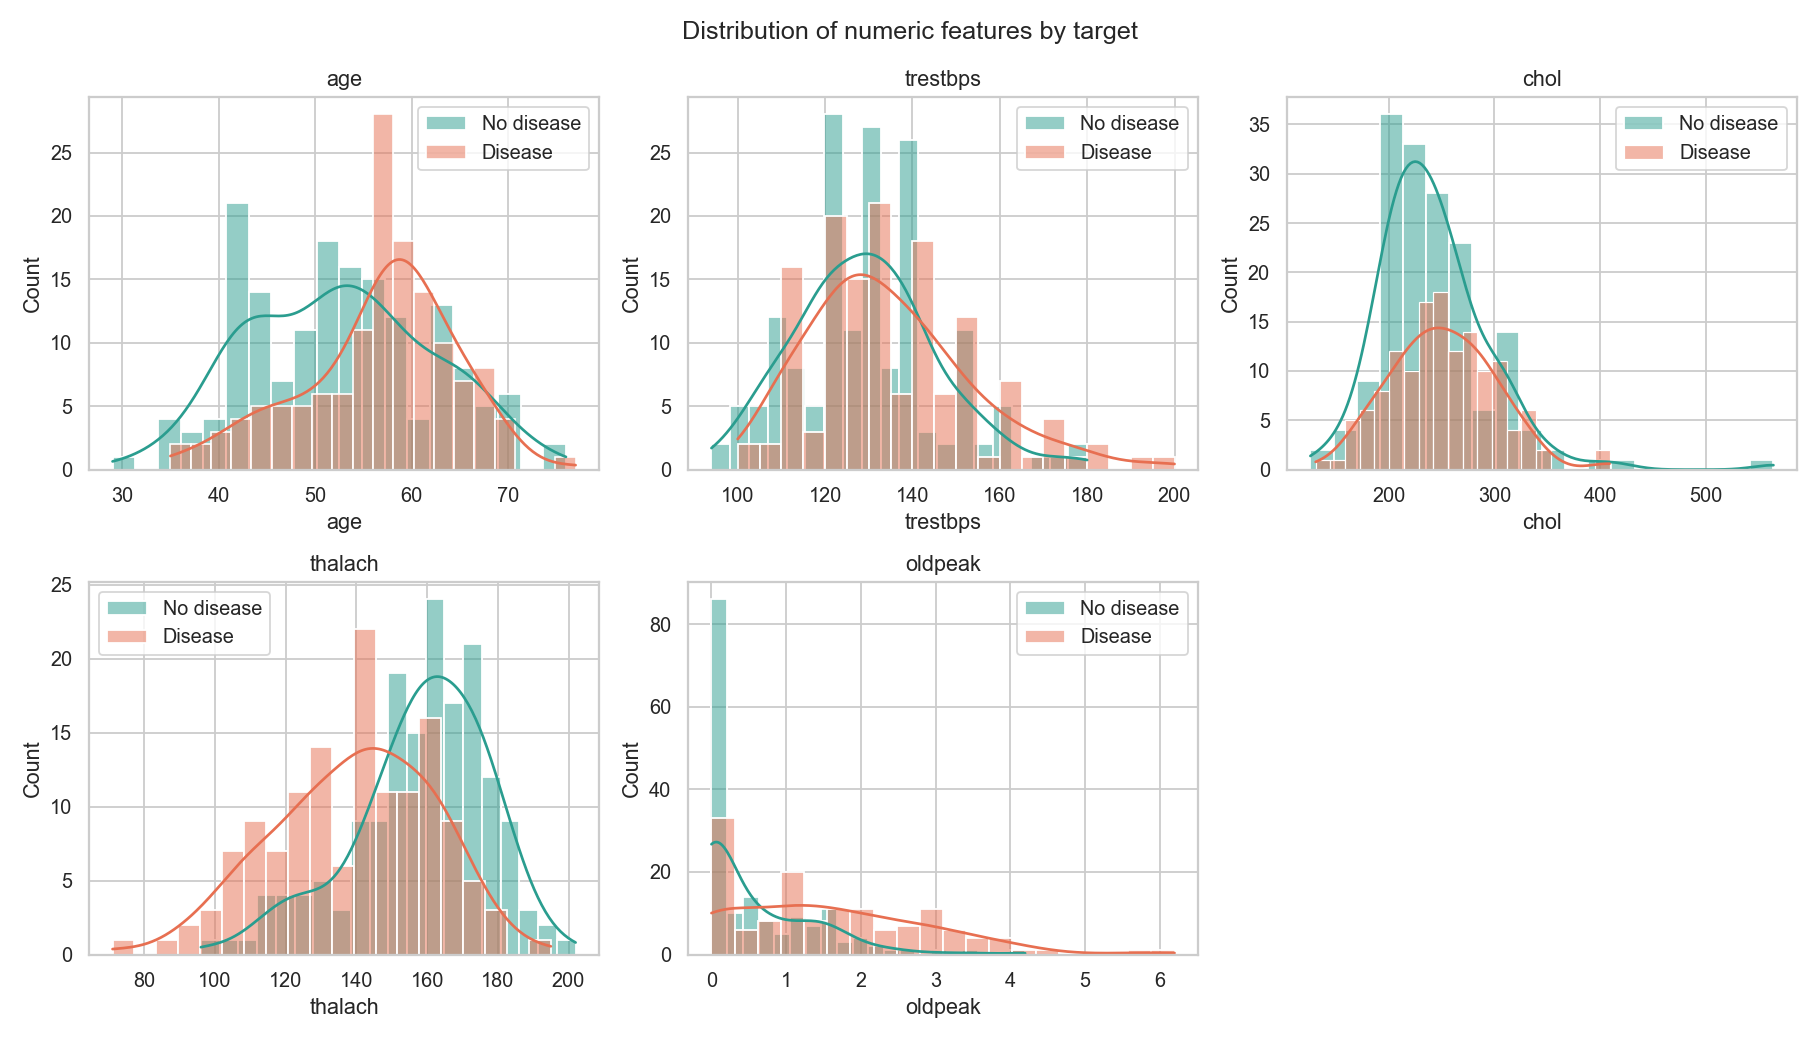

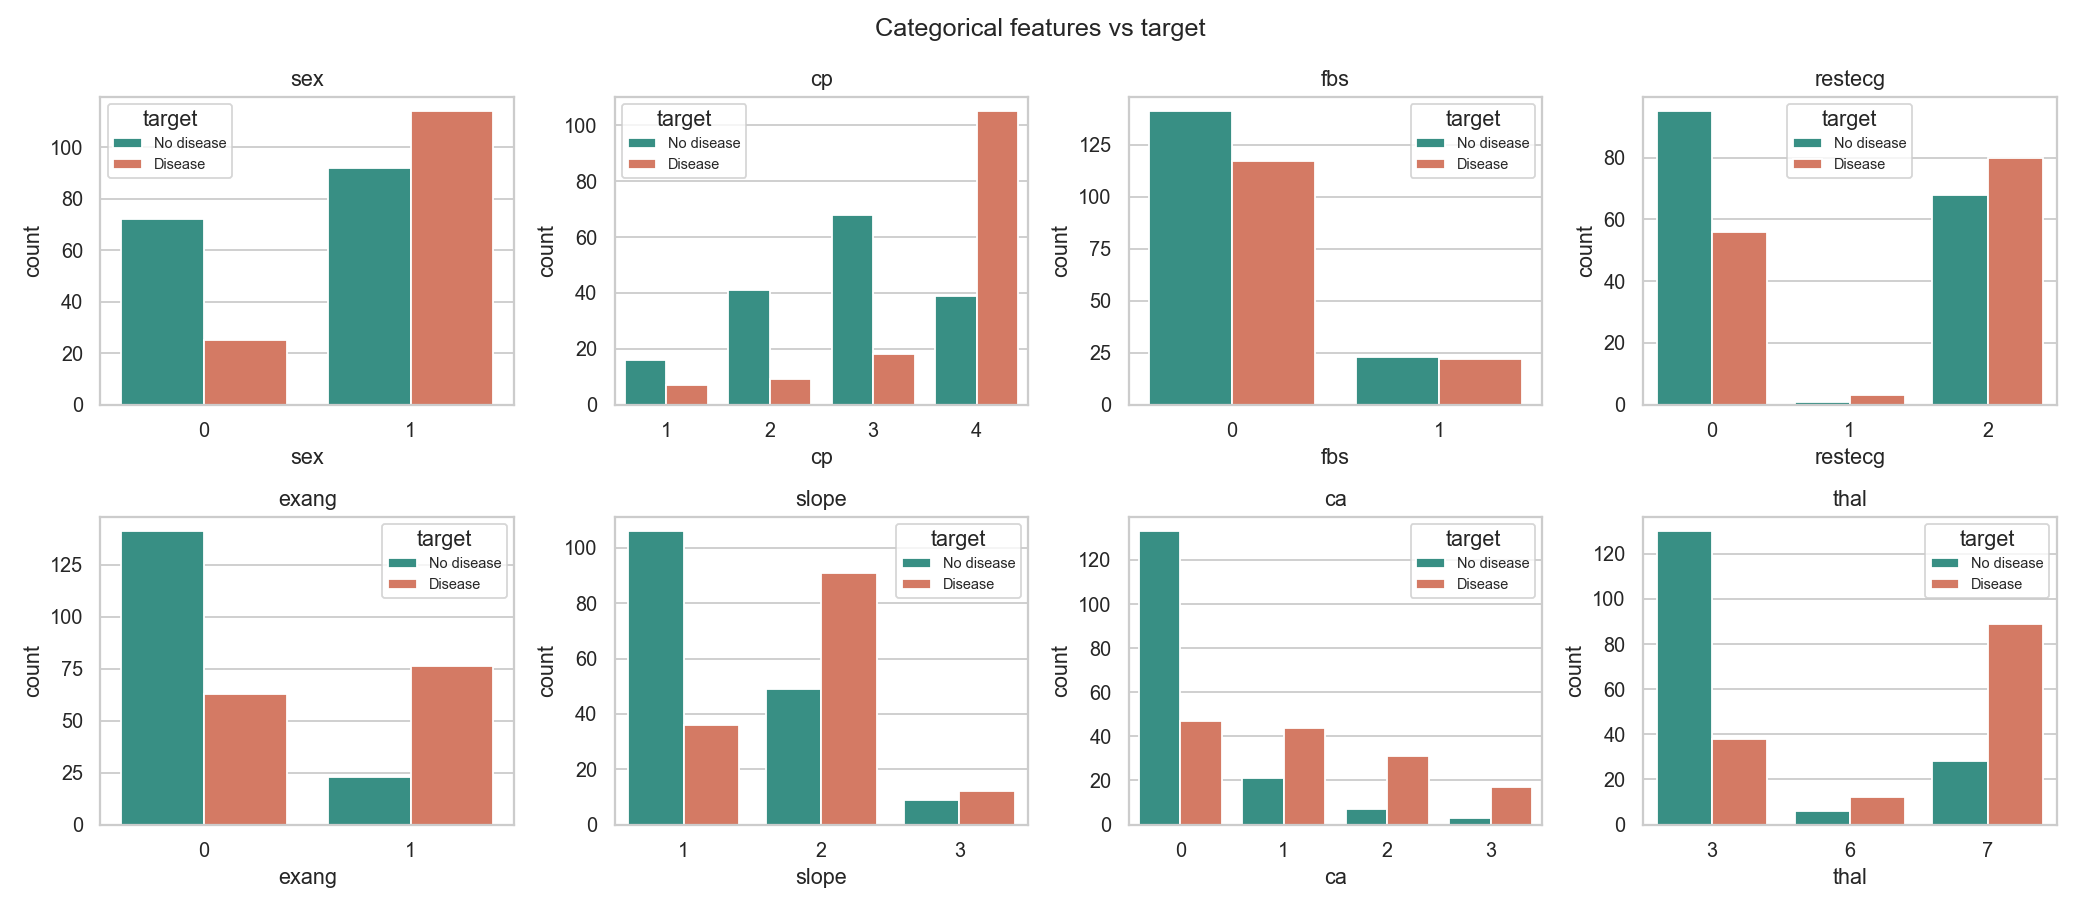

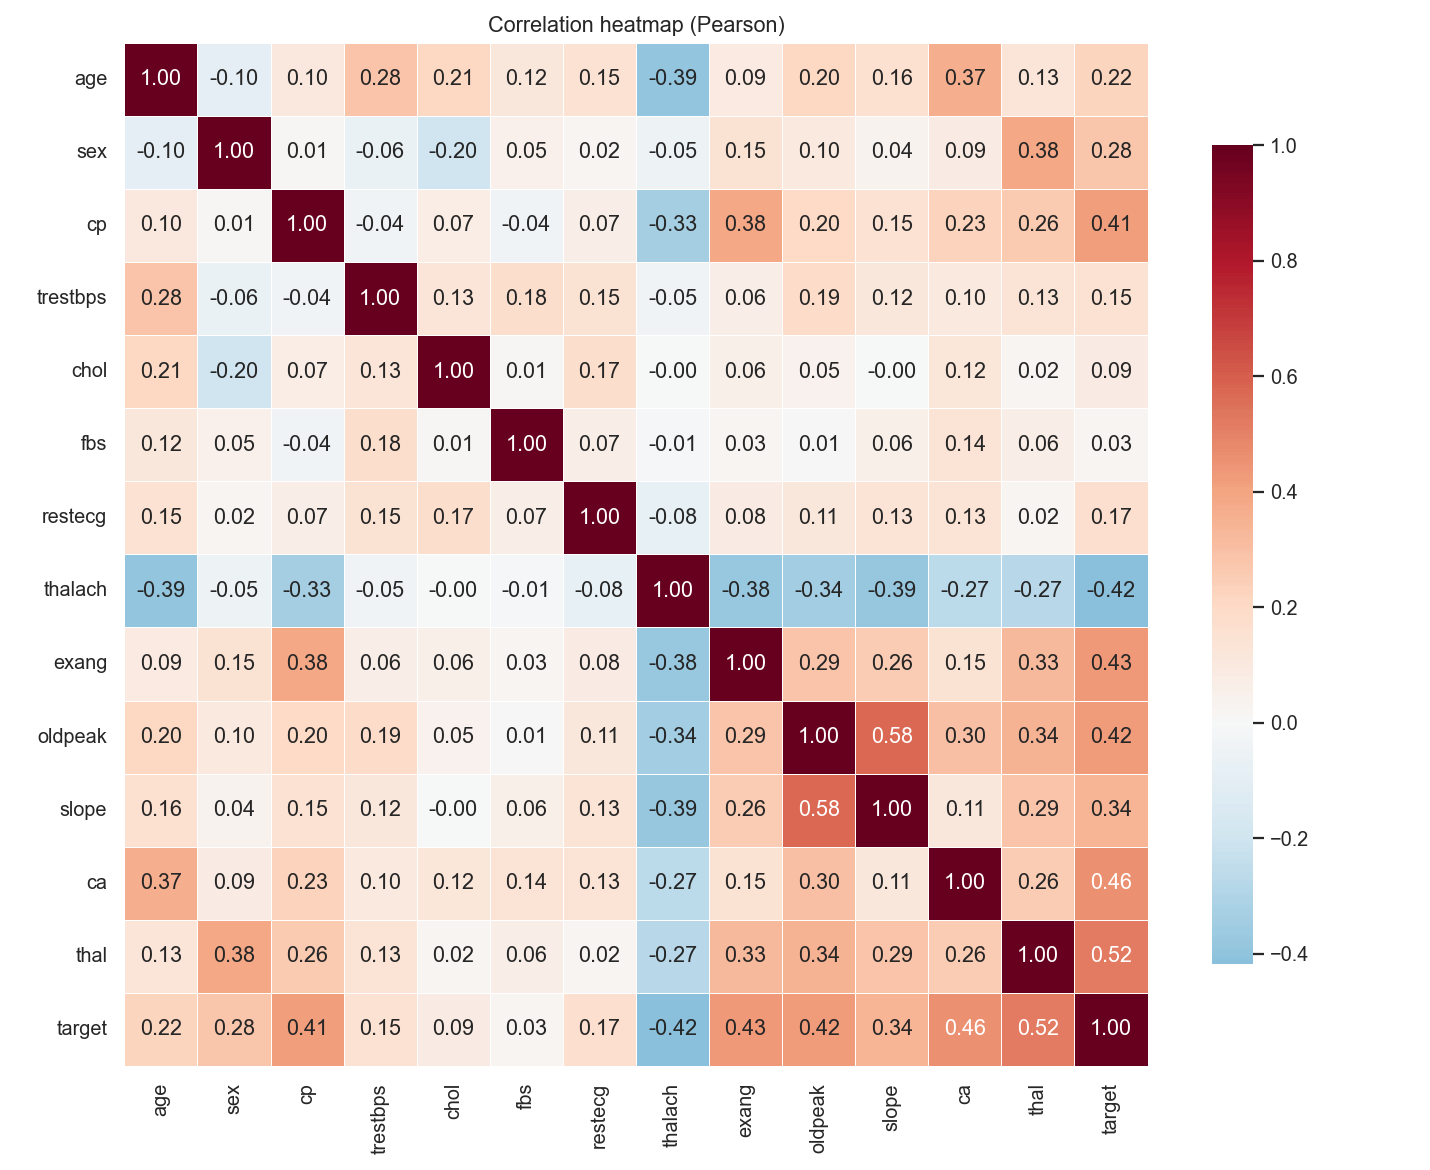

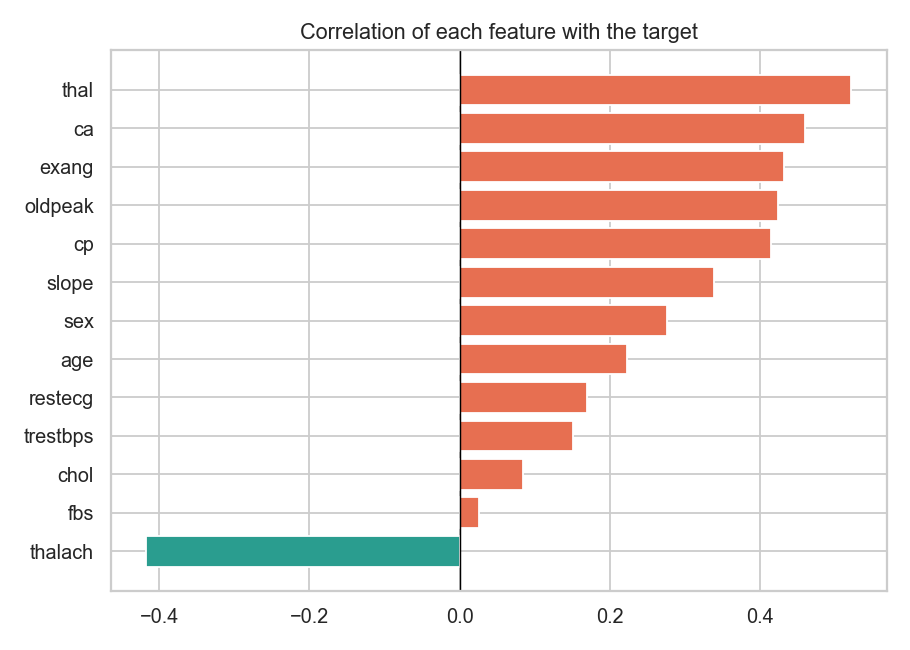

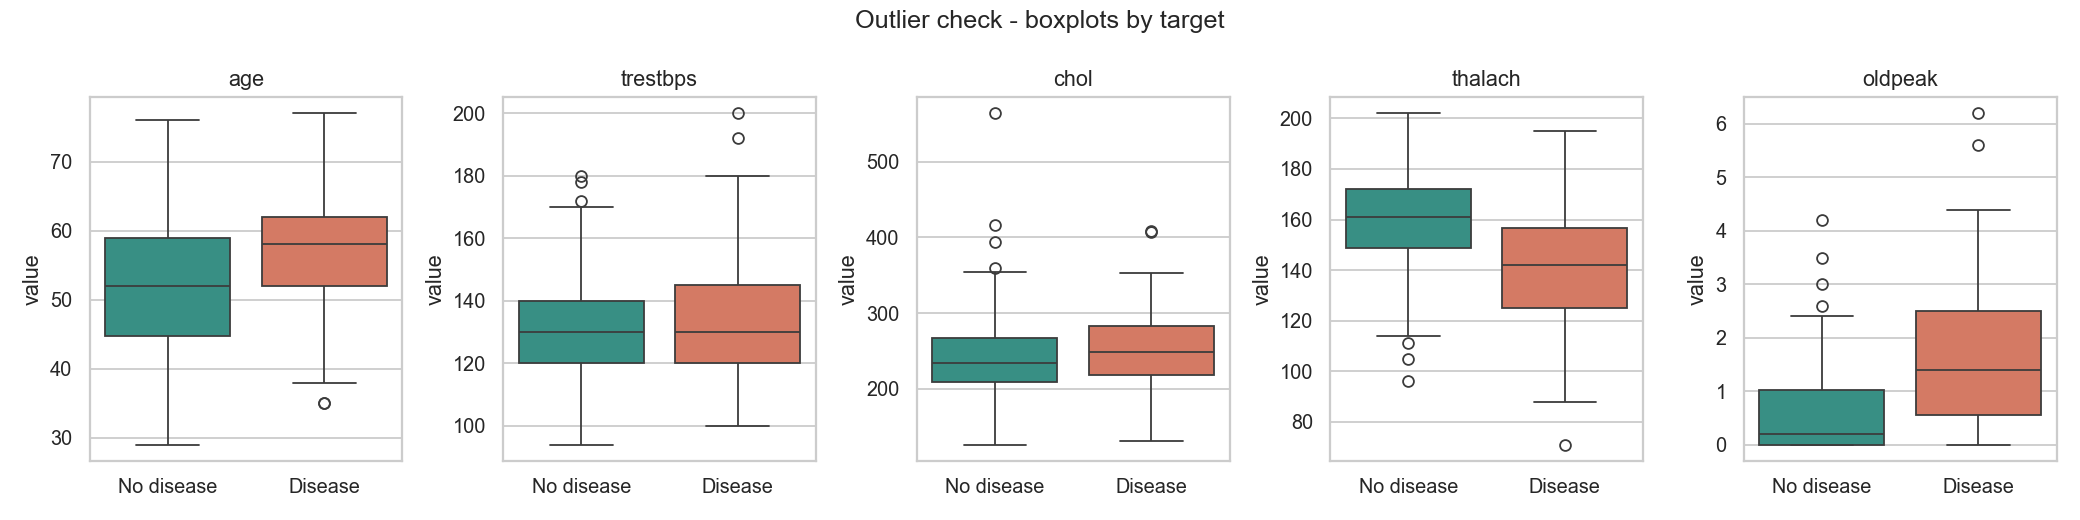

In [6]:
from heart import eda
from IPython.display import Image, display
figs = eda.run_eda()
for f in figs:
    display(Image(filename=str(f)))

## Observations
* **cp = 4 (asymptomatic chest pain)**, **exang = 1**, **thal = 7 (reversible defect)** and **ca > 0** are strongly associated with disease.
* **thalach** (max heart rate) is lower for patients with disease, **oldpeak** is higher.
* `chol` and `fbs` have very weak correlation with the target.
* No feature pair is so highly correlated (|r| > 0.6) that it must be removed.
* A few outliers in `chol` (> 500) and `trestbps` are clinically possible, so they are kept and handled by the scaler.

These observations motivated the engineered feature `hr_pct_max = thalach / (220 - age)` (see notebook 02).